In [ ]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np
from scipy.stats import chi2_contingency

In [72]:
columns = [
    "class",
    "cap_shape",
    "cap_surface",
    "cap_color",
    "bruises",
    "odor",
    "gill_attachment",
    "gill_spacing",
    "gill_size",
    "gill_color",
    "stalk_shape",
    "stalk_root",
    "stalk_surface_above_ring",
    "stalk_surface_below_ring",
    "stalk_color_above_ring",
    "stalk_color_below_ring",
    "veil_type",
    "veil_color",
    "ring_number",
    "ring_type",
    "spore_print_color",
    "population",
    "habitat"
]


data = pd.read_csv(
    "../data/agaricus-lepiota.data",
    header=None,
    names=columns
)

In [73]:
data.shape

(8124, 23)

In [74]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8124 entries, 0 to 8123
Data columns (total 23 columns):
 #   Column                    Non-Null Count  Dtype 
---  ------                    --------------  ----- 
 0   class                     8124 non-null   object
 1   cap_shape                 8124 non-null   object
 2   cap_surface               8124 non-null   object
 3   cap_color                 8124 non-null   object
 4   bruises                   8124 non-null   object
 5   odor                      8124 non-null   object
 6   gill_attachment           8124 non-null   object
 7   gill_spacing              8124 non-null   object
 8   gill_size                 8124 non-null   object
 9   gill_color                8124 non-null   object
 10  stalk_shape               8124 non-null   object
 11  stalk_root                8124 non-null   object
 12  stalk_surface_above_ring  8124 non-null   object
 13  stalk_surface_below_ring  8124 non-null   object
 14  stalk_color_above_ring  

In [75]:
data.index

RangeIndex(start=0, stop=8124, step=1)

In [76]:
data.head()

,class,cap_shape,cap_surface,cap_color,bruises,odor,gill_attachment,gill_spacing,gill_size,gill_color,stalk_shape,stalk_root,stalk_surface_above_ring,stalk_surface_below_ring,stalk_color_above_ring,stalk_color_below_ring,veil_type,veil_color,ring_number,ring_type,spore_print_color,population,habitat
0,p,x,s,n,t,p,f,c,n,k,e,e,s,s,w,w,p,w,o,p,k,s,u
1,e,x,s,y,t,a,f,c,b,k,e,c,s,s,w,w,p,w,o,p,n,n,g
2,e,b,s,w,t,l,f,c,b,n,e,c,s,s,w,w,p,w,o,p,n,n,m
3,p,x,y,w,t,p,f,c,n,n,e,e,s,s,w,w,p,w,o,p,k,s,u
4,e,x,s,g,f,n,f,w,b,k,t,e,s,s,w,w,p,w,o,e,n,a,g


In [77]:
data["class"] = data.pop("class")
data.head()

,cap_shape,cap_surface,cap_color,bruises,odor,gill_attachment,gill_spacing,gill_size,gill_color,stalk_shape,stalk_root,stalk_surface_above_ring,stalk_surface_below_ring,stalk_color_above_ring,stalk_color_below_ring,veil_type,veil_color,ring_number,ring_type,spore_print_color,population,habitat,class
0,x,s,n,t,p,f,c,n,k,e,e,s,s,w,w,p,w,o,p,k,s,u,p
1,x,s,y,t,a,f,c,b,k,e,c,s,s,w,w,p,w,o,p,n,n,g,e
2,b,s,w,t,l,f,c,b,n,e,c,s,s,w,w,p,w,o,p,n,n,m,e
3,x,y,w,t,p,f,c,n,n,e,e,s,s,w,w,p,w,o,p,k,s,u,p
4,x,s,g,f,n,f,w,b,k,t,e,s,s,w,w,p,w,o,e,n,a,g,e


In [78]:
data.describe()

,cap_shape,cap_surface,cap_color,bruises,odor,gill_attachment,gill_spacing,gill_size,gill_color,stalk_shape,stalk_root,stalk_surface_above_ring,stalk_surface_below_ring,stalk_color_above_ring,stalk_color_below_ring,veil_type,veil_color,ring_number,ring_type,spore_print_color,population,habitat,class
count,8124,8124,8124,8124,8124,8124,8124,8124,8124,8124,8124,8124,8124,8124,8124,8124,8124,8124,8124,8124,8124,8124,8124
unique,6,4,10,2,9,2,2,2,12,2,5,4,4,9,9,1,4,3,5,9,6,7,2
top,x,y,n,f,n,f,c,b,b,t,b,s,s,w,w,p,w,o,p,w,v,d,e
freq,3656,3244,2284,4748,3528,7914,6812,5612,1728,4608,3776,5176,4936,4464,4384,8124,7924,7488,3968,2388,4040,3148,4208


In [79]:
data.dtypes

cap_shape                   object
cap_surface                 object
cap_color                   object
bruises                     object
odor                        object
gill_attachment             object
gill_spacing                object
gill_size                   object
gill_color                  object
stalk_shape                 object
stalk_root                  object
stalk_surface_above_ring    object
stalk_surface_below_ring    object
stalk_color_above_ring      object
stalk_color_below_ring      object
veil_type                   object
veil_color                  object
ring_number                 object
ring_type                   object
spore_print_color           object
population                  object
habitat                     object
class                       object
dtype: object

In [80]:
(data == "?").sum()

cap_shape                      0
cap_surface                    0
cap_color                      0
bruises                        0
odor                           0
gill_attachment                0
gill_spacing                   0
gill_size                      0
gill_color                     0
stalk_shape                    0
stalk_root                  2480
stalk_surface_above_ring       0
stalk_surface_below_ring       0
stalk_color_above_ring         0
stalk_color_below_ring         0
veil_type                      0
veil_color                     0
ring_number                    0
ring_type                      0
spore_print_color              0
population                     0
habitat                        0
class                          0
dtype: int64

In [81]:
data = data.replace("?",np.nan)
data.isna().sum()

cap_shape                      0
cap_surface                    0
cap_color                      0
bruises                        0
odor                           0
gill_attachment                0
gill_spacing                   0
gill_size                      0
gill_color                     0
stalk_shape                    0
stalk_root                  2480
stalk_surface_above_ring       0
stalk_surface_below_ring       0
stalk_color_above_ring         0
stalk_color_below_ring         0
veil_type                      0
veil_color                     0
ring_number                    0
ring_type                      0
spore_print_color              0
population                     0
habitat                        0
class                          0
dtype: int64

In [82]:
pd.set_option("display.max_columns" , None)
data[data.isna().any(axis =1)]
mask = data["stalk_root"].isna()

print(f"The percentage of missing data is:{data["stalk_root"].isna().mean()*100:.2f}"
      f" and is split roughly like this in relation to the target: \n"
      f"{data.loc[mask , "class"].value_counts(normalize=True)}"
      )
# Values are split 70/30 which means missingness is tied to the target , at this point we will try to inpute the values using a machine learning model because a large chunk of data is missing(30%)

The percentage of missing data is:30.53 and is split roughly like this in relation to the target: 
class
p    0.709677
e    0.290323
Name: proportion, dtype: float64


## Exploratory Data Analysis

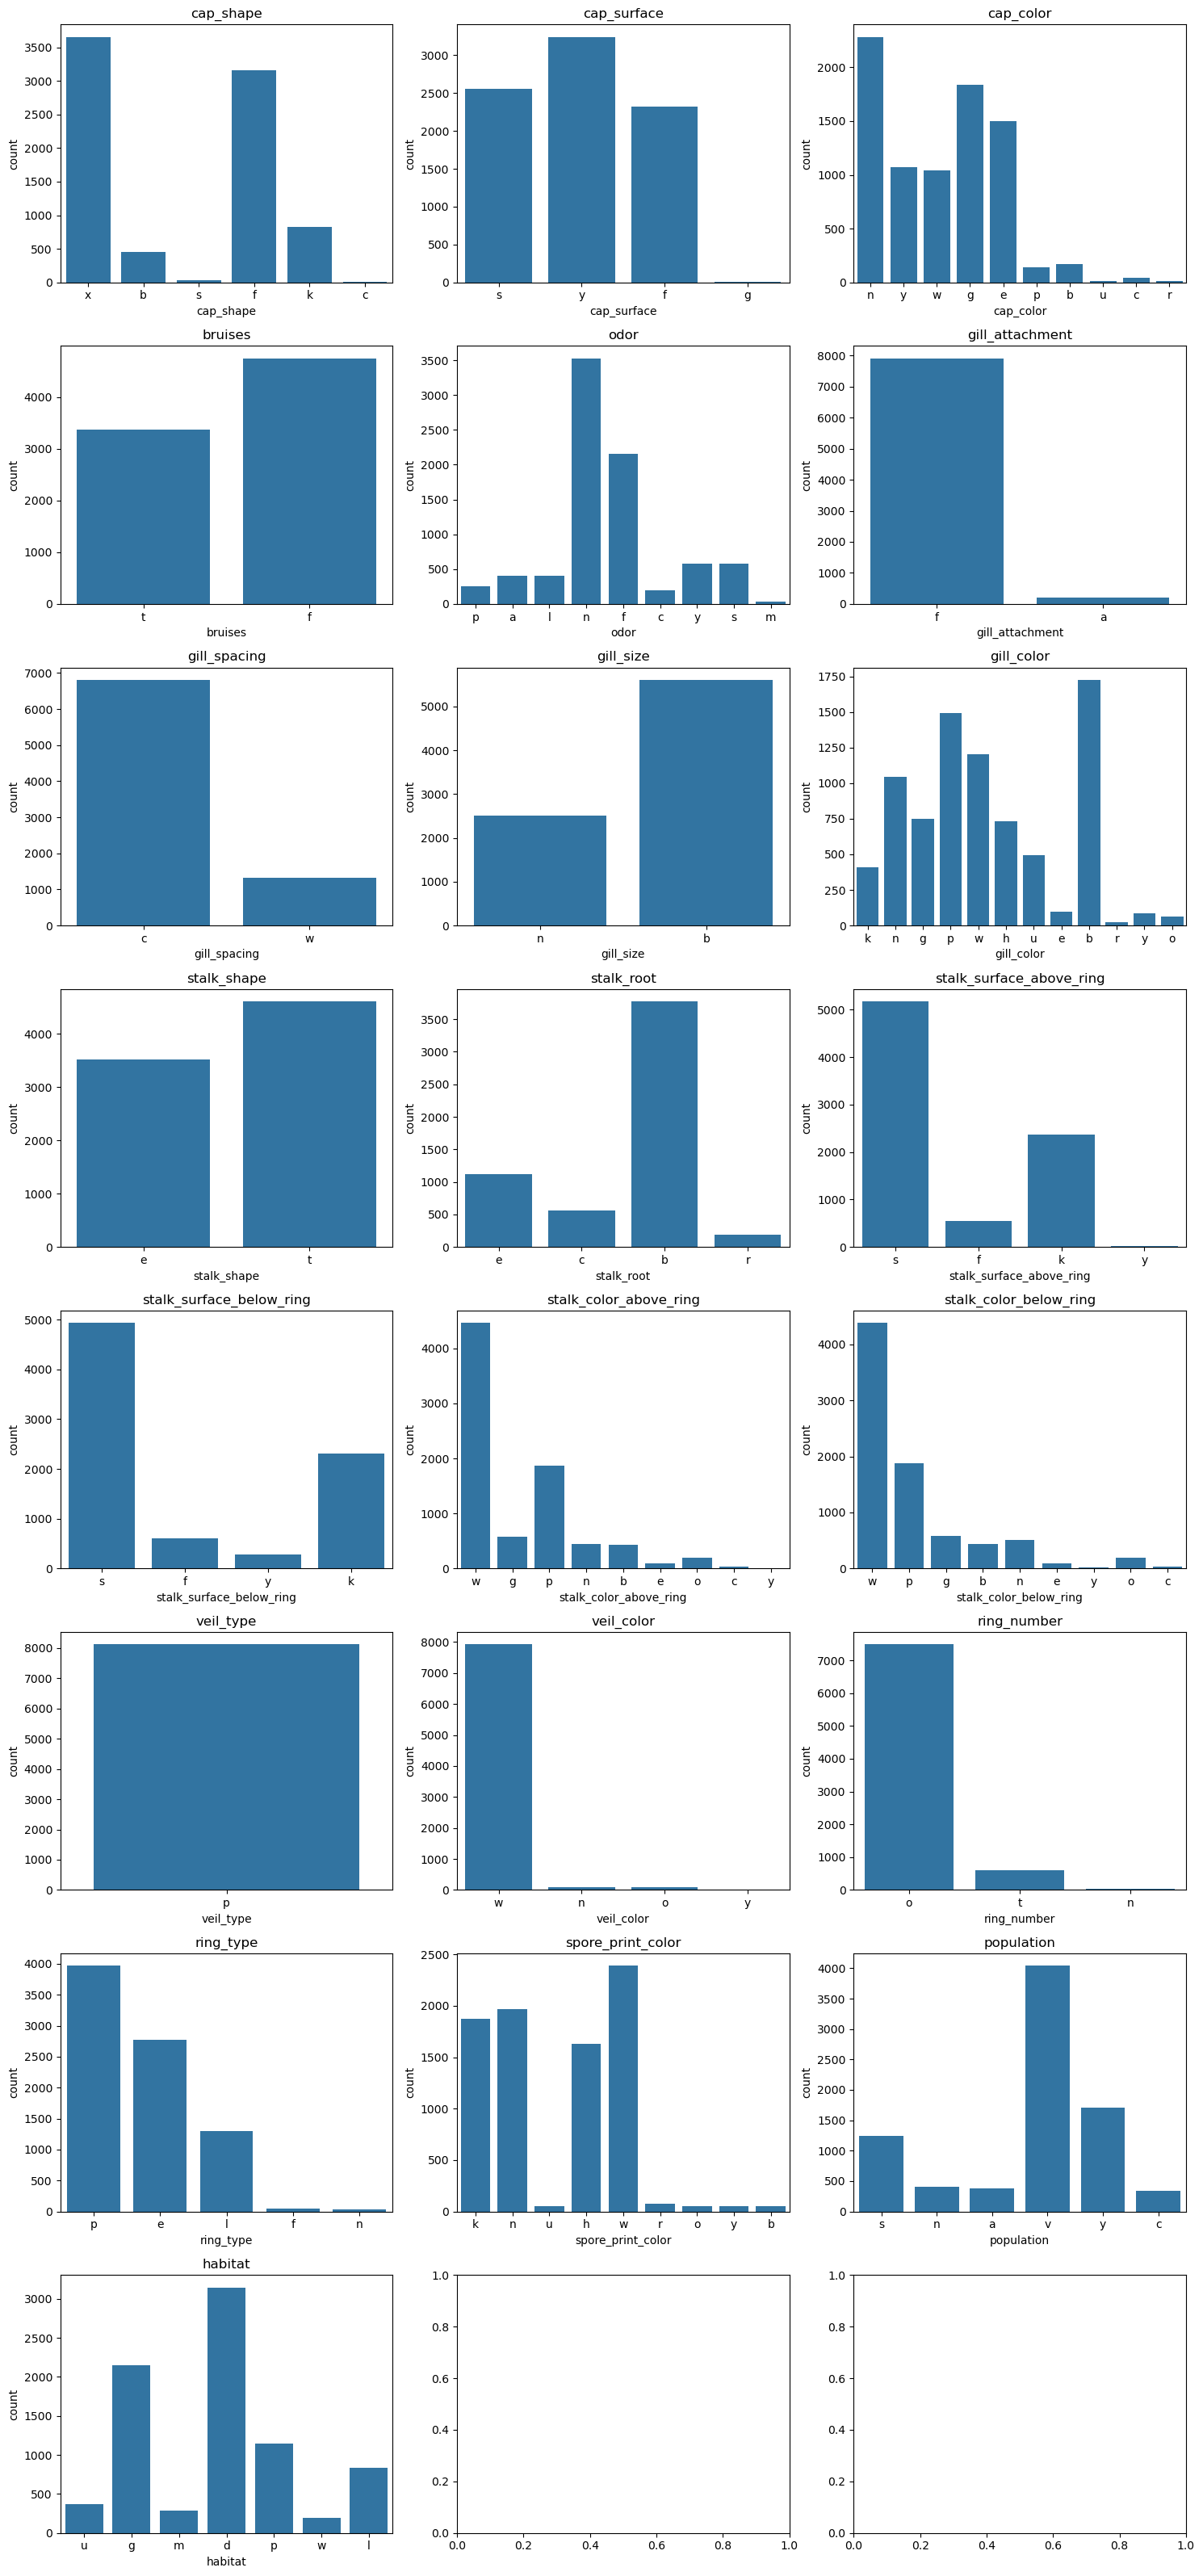

In [83]:
# Plotting some histograms will reveal the distribution of each feature.


features = data.columns.drop("class")

n_columns = 3
n_rows    = int(len(features)/n_columns )+1 


fig , axes = plt.subplots(
    n_rows,
    n_columns,
    figsize = (15,n_rows * 4)
)


for column , ax in zip(features , axes.flat):
    sns.countplot(
        data = data,
        x = column,
        ax = ax
    )
    ax.set_title(column)

plt.tight_layout()
fig.savefig(
    "../images/feature_countplot.png",
    dpi =300,
    bbox_inches = "tight"
)

plt.show()



Veil_type feature has only 1 variable ---> drop because no variance 
Veil_color should also be investigated because  most of the samples are dominated by one variable with the other variables having <50 observations

Below we will explore the variations of disctict variables on these columns:

1. veil_type
2. veil_color
3. ring_number
4. gill_attachment

and drop any column if necessary before imputing any missing values on the stalk_root column.


In [84]:
cols = ["veil_type","veil_color","ring_number","gill_attachment"]

dict_prop = {}

for col in cols:
    dict_prop[col] = data[col].value_counts(normalize=True)*100

summary = pd.DataFrame.from_dict(dict_prop)
summary.replace(np.nan,"-")

,veil_type,veil_color,ring_number,gill_attachment
a,-,-,-,2.584934
f,-,-,-,97.415066
n,-,1.181684,0.443131,-
o,-,1.181684,92.171344,-
p,100.0,-,-,-
t,-,-,7.385524,-
w,-,97.538159,-,-
y,-,0.098474,-,-


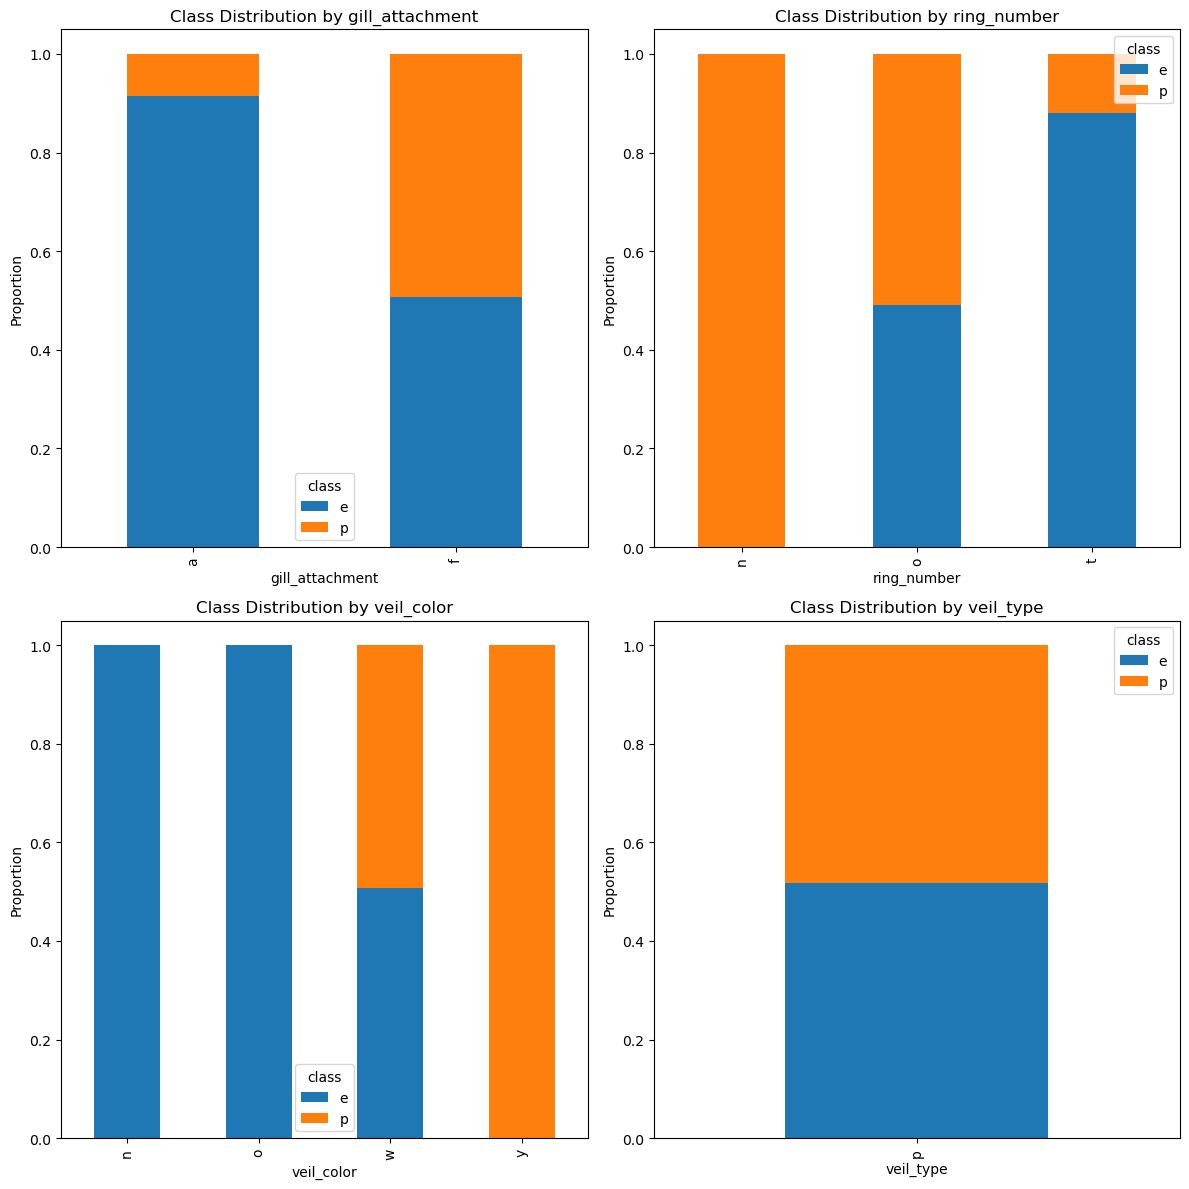

In [85]:

# Let's investigate how these categorical features relate to the target.
fig, axes = plt.subplots(2, 2, figsize=(12, 12))

columns = ["gill_attachment", "ring_number", "veil_color", "veil_type"]

for feature, ax in zip(columns, axes.flat):
    pd.crosstab(
        data[feature],
        data["class"],
        normalize="index"
    ).plot(kind="bar", stacked=True, ax=ax)

    ax.set_title(f"Class Distribution by {feature}")
    ax.set_ylabel("Proportion")
    ax.set_xlabel(feature)

plt.tight_layout()
plt.show()


Although some feature categories are less represented than others, several show a strong association with the target classes (`p` and `e`). I will drop `veil_type` because it has no variation in its values in relation to the target, containing only one class (`p`).

However, we cannot rely solely on visual inspection to assess every feature's relationship with the target. Therefore, we use the chi-squared test to test for independence and Cramér's V to measure the strength of association.

In [86]:
data = data.drop(columns=["veil_type"])

In [87]:
target = "class"
features = data.drop(columns=[target]).columns

results = []

for feature in features:
    table = pd.crosstab(data[feature], data[target])
    
    chi2, p_value, dof, expected = chi2_contingency(table)

    
    n = table.to_numpy().sum()
    r, c = table.shape

    cramers_v = np.sqrt(
        chi2 / (n * min(r - 1, c - 1))
    )

    results.append({
        "feature": feature,
        "chi2": chi2,
        "p_value": p_value,
        "cramers_v": cramers_v,
    })

results_df = pd.DataFrame(results)

results_df = results_df.sort_values(
    "cramers_v", ascending=False
)

results_df.reset_index(drop=True)

,feature,chi2,p_value,cramers_v
0,odor,7659.726740,0.000000e+00,0.971005
1,spore_print_color,4602.033170,0.000000e+00,0.752645
2,gill_color,3765.714086,0.000000e+00,0.680830
3,ring_type,2956.619278,0.000000e+00,0.603271
4,stalk_surface_above_ring,2808.286287,0.000000e+00,0.587944
5,stalk_surface_below_ring,2684.474076,0.000000e+00,0.574837
6,gill_size,2366.834257,0.000000e+00,0.539758
7,stalk_color_above_ring,2237.898496,0.000000e+00,0.524850
8,stalk_color_below_ring,2152.390891,0.000000e+00,0.514725
9,bruises,2041.415647,0.000000e+00,0.501280


Using the chi-squared test and Cramér's V, we can see that features like `odor`, `spore_print_color`, and `gill_color` have strong associations with the target and very small p-values, indicating evidence of dependence. Other features, such as `stalk_shape` and `gill_attachment`, have weaker associations despite their small p-values. However, weaker association does not necessarily mean poor predictive power, which we will evaluate through experimentation and model validation.